In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'core').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.figsize': (7, 4)})
FIG = ROOT / 'results' / 'figures'; DATA = ROOT / 'results' / 'data'

# 01 — Replicating Guo & Conitzer (2010)

**Paper.** *Strategy-proof Allocation of Multiple Items between Two Agents without Payments or
Priors* (AAMAS 2010). Two agents, $m$ divisible items, additive normalised valuations, no money,
no prior. A mechanism is $\alpha$-competitive if its welfare is at least $\alpha$ times the
first-best welfare at every type profile.

**What this notebook checks**

| Claim in the paper | Our result |
|---|---|
| Thm 1: no strategy-proof mechanism beats **0.841** (LP, $N=50$) | reproduced: $0.841225$ — but the value *decreases* with $N$ |
| Thm 2: LIP(2) is between **0.828 and 0.829** | reproduced and sharpened: $\alpha(2)\in[0.8281462,\,0.8281472]$ |
| Fig. 1: bounds for $m=3\ldots100$ items | reproduced |
| (implicit) $a=2$ is a good choice | **not optimal**: $a^\star\approx 2.1013$ gives $\alpha^\star\approx 0.82939$ |

All code lives in `core/` (`lip.py`, `lp.py`); this notebook only calls it and plots.

## 1. The LIP mechanism in one picture

With probability $\tfrac12$ an agent is the *dictator*. She has one unit of artificial currency
and buys proportions of the items against the price schedule $f(t)=at+b$ (per item, $t$ =
currency already spent on that item). Normalising $\int_0^1 dt/f(t)=1$ gives $b=a/(e^a-1)$, so
spending $t$ on an item buys $Q(t)=\ln(1+at/b)/a$ of it. The other agent gets whatever is left.

The set of bundles a dictator can afford — the **menu** — is $\{(z_1,z_2): c(z_1)+c(z_2)\le 1\}$
with $c=Q^{-1}$. Because the menu is fixed and the dictator gets her favourite point of it,
truth-telling is dominant (nothing the other agent says changes the menu). This observation is
the key to Part B.

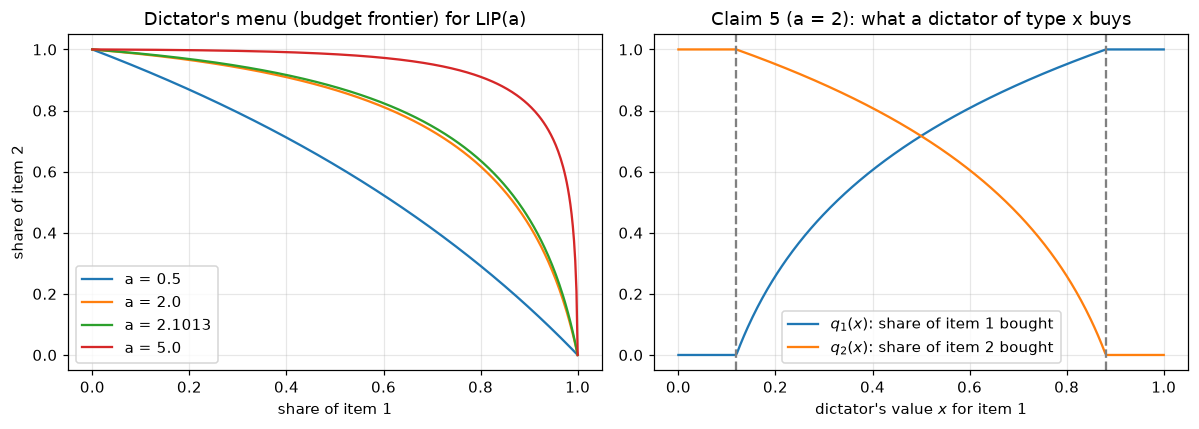

Claim 5 regime switches at 0.119 and 0.881; Example 2: type (0.5,0.5) buys 0.717 of each item


In [2]:
from core import lip
a = 2.0
z = np.linspace(0, 1, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for aa in (0.5, 2.0, 2.1013, 5.0):
    # frontier: c(z1) + c(z2) = 1  ->  z2 = Q(1 - c(z1))
    z2 = lip.Q(1 - lip.cost(z, aa), aa)
    ax[0].plot(z, z2, label=f"a = {aa}")
ax[0].set(xlabel="share of item 1", ylabel="share of item 2", title="Dictator's menu (budget frontier) for LIP(a)")
ax[0].legend()
x = np.linspace(0, 1, 400)
q1, q2 = lip.bundle_additive(x, a)
ax[1].plot(x, q1, label="$q_1(x)$: share of item 1 bought"); ax[1].plot(x, q2, label="$q_2(x)$: share of item 2 bought")
lo, hi = lip.regime_thresholds(a)
for v in (lo, hi):
    ax[1].axvline(v, ls="--", c="gray")
ax[1].set(xlabel="dictator's value $x$ for item 1", title="Claim 5 (a = 2): what a dictator of type x buys")
ax[1].legend(); plt.tight_layout(); plt.savefig(FIG / "01_menu_and_claim5.png"); plt.show()
print(f"Claim 5 regime switches at {lo:.3f} and {hi:.3f}; Example 2: type (0.5,0.5) buys {lip.bundle_additive(0.5, 2.0)[0]:.3f} of each item")

## 2. Theorem 2: the competitive ratio of LIP(2)

$\alpha(a)=\min_{1\ge x\ge y\ge 0} S(x,y)/(x+1-y)$. The paper brackets it on a uniform grid
(lower bound from the worst corner of each cell using monotonicity of $p_1,p_2$; upper bound =
exact ratio at grid points). We implement exactly that (`lip.sandwich`) **and** an adaptive
version that only refines cells whose bound is loose (`lip.sandwich_adaptive`). The uniform
grid needs $N\approx 20\,000$ (i.e. $2\cdot10^8$ cells) to certify the paper's "$\ge 0.828$";
the adaptive one does it with a few thousand cells.

In [3]:
import time
rows = []
for N in (50, 200, 1000, 4000):
    t = time.time(); lo, up, cl, pu = lip.sandwich(2.0, N)
    rows.append(dict(method=f"uniform N={N}", lower=lo, upper=up, argmin=tuple(np.round(pu, 4)), seconds=round(time.time()-t, 3)))
for tol in (1e-4, 1e-6):
    t = time.time(); lo, up, arg, n = lip.sandwich_adaptive(2.0, tol=tol)
    rows.append(dict(method=f"adaptive tol={tol:g}", lower=lo, upper=up, argmin=tuple(np.round(arg, 4)), seconds=round(time.time()-t, 3)))
pd.DataFrame(rows)

,method,lower,upper,argmin,seconds
0,uniform N=50,0.792237,0.828181,"(0.4, 0.0)",0.002
1,uniform N=200,0.820785,0.828151,"(0.405, 0.0)",0.004
2,uniform N=1000,0.826671,0.828147,"(0.407, 0.0)",0.128
3,uniform N=4000,0.827778,0.828147,"(0.4075, 0.0)",1.845
4,adaptive tol=0.0001,0.828047,0.828147,"(0.4073, 0.0)",0.006
5,adaptive tol=1e-06,0.828146,0.828147,"(0.4074, 0.0)",0.034


So $0.8281462 \le \alpha(2) \le 0.8281472$: the paper's $[0.828, 0.829]$ is correct, and the
worst case is at $(x,y)\approx(0.4074, 0)$ — agent 2 only wants item 2, agent 1 is *mildly*
in favour of item 2 (so as dictator she buys mostly item 2, which is exactly what agent 2 wanted).

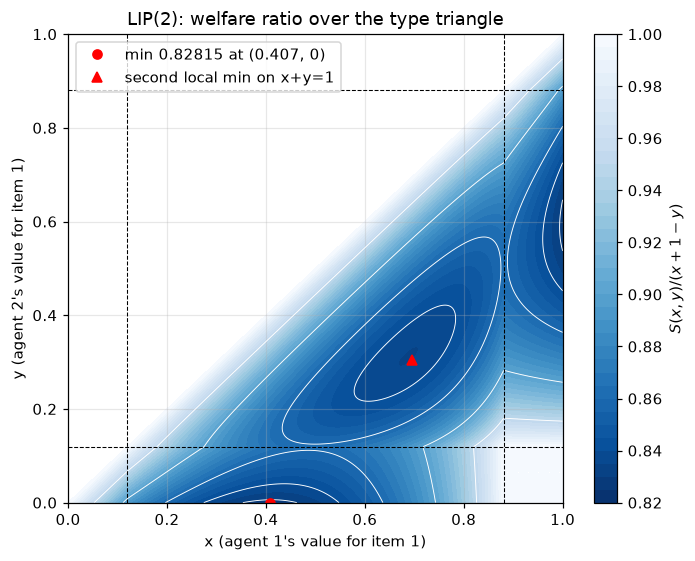

In [4]:
# the ratio over the triangle, as in the figure of our Part-A report
g = np.linspace(0, 1, 401)
X, Y = np.meshgrid(g, g, indexing="ij")
R = np.where(X >= Y, lip.ratio(X, Y, 2.0), np.nan)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
cs = ax.contourf(X, Y, R, levels=np.linspace(0.82, 1.0, 37), cmap="Blues_r")
plt.colorbar(cs, label="$S(x,y)/(x+1-y)$")
ax.contour(X, Y, R, levels=[0.83, 0.84, 0.86, 0.9, 0.95], colors="w", linewidths=0.6)
lo_, hi_ = lip.regime_thresholds(2.0)
for v in (lo_, hi_):
    ax.axvline(v, ls="--", c="k", lw=0.7); ax.axhline(v, ls="--", c="k", lw=0.7)
ax.plot([0.4074], [0], "ro", label="min 0.82815 at (0.407, 0)")
ax.plot([0.6955], [0.3045], "r^", label="second local min on x+y=1")
ax.set(xlabel="x (agent 1's value for item 1)", ylabel="y (agent 2's value for item 1)", title="LIP(2): welfare ratio over the type triangle")
ax.legend(loc="upper left"); plt.tight_layout(); plt.savefig(FIG / "01_triangle_a2.png"); plt.show()

## 3. Is $a=2$ the best LIP mechanism? No.

The paper evaluates LIP(2) only. Scanning $a$ (certified brackets, `experiments/lip_alpha_scan.py`)
shows two competing worst-case branches:

* **edge branch** $\beta(a)$: $y=0$ (agent 2 all-in on item 2), $x\approx 0.41$ — binding for small $a$;
* **anti-diagonal branch**: $x+y=1$ — binding for large $a$. This is exactly the profile family
  used in the paper's Claim 8, so on this branch $\alpha(a)=\theta(a)$, the paper's *intrinsic value*.

Numerically $\alpha(a)=\min\{\theta(a),\beta(a)\}$, and the best LIP sits where the two branches
cross: $a^\star\approx 2.1013$, $\alpha^\star\approx 0.82939$ (vs $0.82815$ at $a=2$). Small
gain, but it tells us *why* the optimum is where it is.

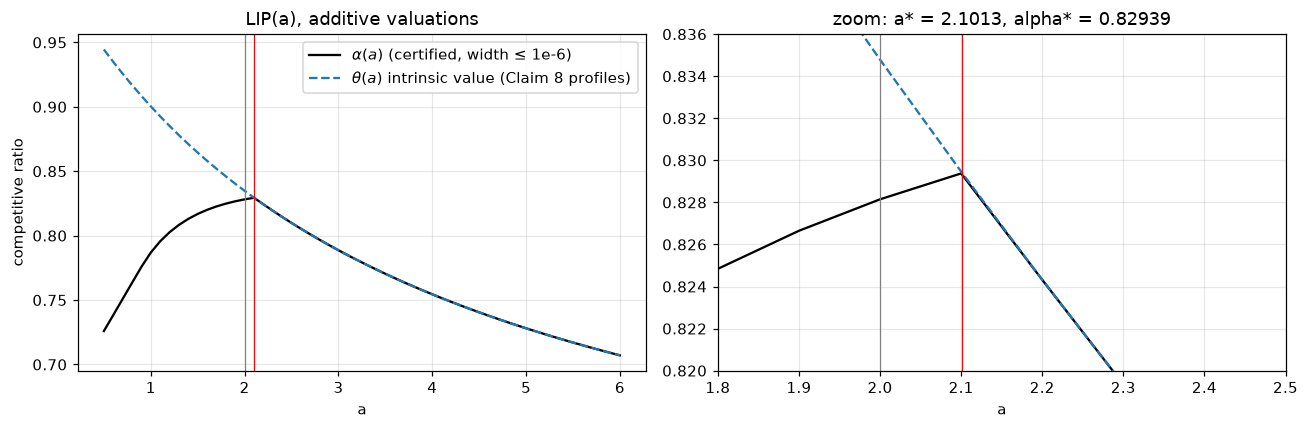

,a,alpha_lower,alpha_upper,x_worst,y_worst,theta_upper
10,1.5,0.816854,0.816855,0.355,0.000,0.864450
11,1.6,0.820028,0.820029,1.000,0.635,0.858074
12,1.7,0.822659,0.822660,0.376,0.000,0.851932
13,1.8,0.824841,0.824842,0.387,0.000,0.846011
14,1.9,0.826650,0.826651,0.397,0.000,0.840300
15,2.0,0.828146,0.828147,0.407,0.000,0.834787
16,2.1,0.829377,0.829378,0.417,0.000,0.829463
17,2.2,0.824287,0.824319,0.701,0.299,0.824319
18,2.3,0.819314,0.819345,0.707,0.292,0.819345
19,2.4,0.814503,0.814533,0.713,0.286,0.814533


In [5]:
import json
scan = pd.read_csv(DATA / "lip_alpha_scan.csv"); opt = json.loads((DATA / "lip_alpha_opt.json").read_text())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(scan.a, scan.alpha_upper, "k-", label=r"$\alpha(a)$ (certified, width ≤ 1e-6)")
ax[0].plot(scan.a, scan.theta_upper, "--", label=r"$\theta(a)$ intrinsic value (Claim 8 profiles)")
ax[0].axvline(opt["a_star"], c="r", lw=0.8); ax[0].axvline(2.0, c="gray", lw=0.8)
ax[0].set(xlabel="a", ylabel="competitive ratio", title="LIP(a), additive valuations"); ax[0].legend()
ax[1].plot(scan.a, scan.alpha_upper, "k-"); ax[1].plot(scan.a, scan.theta_upper, "--")
ax[1].set(xlim=(1.8, 2.5), ylim=(0.82, 0.836), xlabel="a", title=f"zoom: a* = {opt['a_star']:.4f}, alpha* = {opt['alpha_upper']:.5f}")
ax[1].axvline(opt["a_star"], c="r", lw=0.8); ax[1].axvline(2.0, c="gray", lw=0.8)
plt.tight_layout(); plt.savefig(FIG / "01_alpha_of_a.png"); plt.show()
scan[["a", "alpha_lower", "alpha_upper", "x_worst", "y_worst", "theta_upper"]].query("1.5 <= a <= 3").round(6)

Note how the worst-case profile `(x_worst, y_worst)` jumps from the edge $y=0$ to the
anti-diagonal ($x+y=1$) at $a^\star$, and that `alpha_upper == theta_upper` beyond it.

## 4. Theorem 1: the LP upper bound, and why "0.841" is really a grid artefact

The paper restricts types to the grid $\{j/N\}$ with $N=50$ and solves an LP for the best
strategy-proof mechanism on that grid. Since restricting the type space can only help the
mechanism, the LP value is an upper bound on every strategy-proof mechanism — **for every $N$**.
So the *smallest* value over $N$ is the valid bound to quote, and it keeps decreasing:

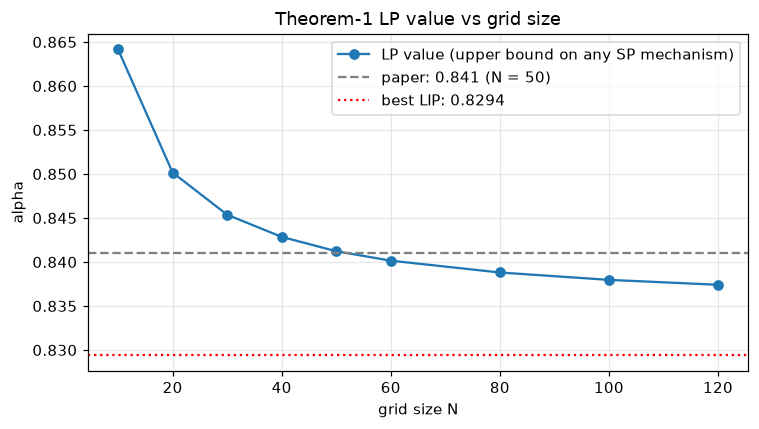

,N,eps,alpha,binding,seconds
0,10,0.0,0.86415,11,0.01423
1,20,0.0,0.85017,20,0.04760
2,30,0.0,0.84537,29,0.23833
3,40,0.0,0.84285,39,0.68996
4,50,0.0,0.84123,48,3.14013
5,60,0.0,0.84015,57,4.61265
6,80,0.0,0.83881,77,18.93374
7,100,0.0,0.83797,109,81.56705
8,120,0.0,0.83741,114,195.99244


In [6]:
conv = pd.read_csv(DATA / "lp_convergence_eps0.csv")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(conv.N, conv.alpha, "o-", label="LP value (upper bound on any SP mechanism)")
ax.axhline(0.841, c="gray", ls="--", label="paper: 0.841 (N = 50)")
ax.axhline(opt["alpha_upper"], c="r", ls=":", label=f"best LIP: {opt['alpha_upper']:.4f}")
ax.set(xlabel="grid size N", ylabel="alpha", title="Theorem-1 LP value vs grid size"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "01_lp_convergence.png"); plt.show()
conv.round(5)

In [7]:
# crude extrapolation in 1/N (the limit N -> infinity is the bound for the continuous type space)
c = conv[conv.N >= 50]
A = np.vstack([np.ones(len(c)), 1 / c.N, 1 / c.N**2]).T
coef, *_ = np.linalg.lstsq(A, c.alpha, rcond=None)
print(f"fit alpha(N) ~ {coef[0]:.4f} + {coef[1]:.3f}/N + {coef[2]:.2f}/N^2   ->  extrapolated limit ~ {coef[0]:.4f}")
print("gap between best LIP and the extrapolated LP limit:", round(coef[0] - opt['alpha_upper'], 4))

fit alpha(N) ~ 0.8346 + 0.351/N + -0.86/N^2   ->  extrapolated limit ~ 0.8346
gap between best LIP and the extrapolated LP limit: 0.0052


**Take-away.** The honest statement of Theorem 1 is "at most $\alpha_{LP}(N)$ for the largest
$N$ solved", which is noticeably below $0.841$; the best LIP mechanism is therefore even closer to
optimal than the paper claims. (Notebook 02 digs into the LP's structure.)

## 5. Three or more items (Theorem 3 / Figure 1)

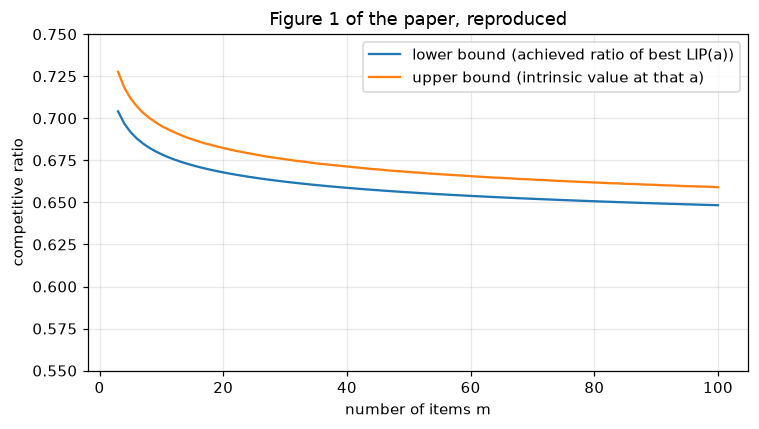

,m,best a,lower,upper
0,3,5.02,0.7041,0.7276
1,4,5.44,0.6969,0.7183
2,5,5.75,0.6919,0.7119
7,10,6.66,0.6786,0.6954
17,20,7.51,0.6678,0.6824
47,50,8.61,0.6560,0.6681
97,100,9.42,0.6483,0.6590


In [8]:
ms = np.arange(3, 101)
A_grid = np.arange(0.01, 20.001, 0.01)
theta = np.array([lip.theta_bounds(aa, 2000) for aa in A_grid])       # (lower, upper) per a
lower_best, upper_at_best, a_best = [], [], []
for m in ms:
    b = lip.b_of(A_grid)
    lb = (A_grid + b) / (A_grid + 2 * m * b) * theta[:, 0]
    i = int(np.argmax(lb)); lower_best.append(lb[i]); upper_at_best.append(theta[i, 1]); a_best.append(A_grid[i])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ms, lower_best, label="lower bound (achieved ratio of best LIP(a))"); ax.plot(ms, upper_at_best, label="upper bound (intrinsic value at that a)")
ax.set(xlabel="number of items m", ylabel="competitive ratio", ylim=(0.55, 0.75), title="Figure 1 of the paper, reproduced"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "01_figure1_m_items.png"); plt.show()
pd.DataFrame({"m": ms, "best a": a_best, "lower": lower_best, "upper": upper_at_best}).iloc[[0, 1, 2, 7, 17, 47, 97]].round(4)

Matches the paper's Figure 1 (ratios between 0.6 and 0.7, decreasing in $m$). Interesting: the
best $a$ grows with $m$ — with more items the dictator should face steeper prices.

## Summary

* Every number in the paper is reproduced. The Theorem-2 bracket is tightened to $10^{-6}$ with
  adaptive refinement.
* $a=2$ is slightly sub-optimal; the optimum $a^\star\approx2.1013$ is where the paper's own
  "intrinsic value" curve $\theta(a)$ meets the edge branch $\beta(a)$.
* The 0.841 upper bound depends on the grid; finer grids give a smaller (better) bound, so LIP is
  closer to optimal than the paper states.